# plot_AOD_vs_tas — zonal-mean stratospheric AOD across GeoMIP models

Python port of `plot_AOD_vs_tas.m`. Plots the 2090–2100 zonal-mean
stratospheric AOD for each GeoMIP model, then interpolates them onto a common
2° latitude grid and computes the inter-model standard deviation.

Inputs are external/provided (`../GeoMIP_G6Sulfur/AOD_GeoMIP.mat`,
`2deg_tas.mat`) → read as `.mat`.

**Note:** the original MATLAB ends with a `figure(3)` loop
`for i=1:91, scatter(sulf_delta_std1(i,:), fc2(i,:))` that indexes a
81-row colormap with `i` up to 91 (out of range) and scatters mismatched
lengths — a non-functional fragment that produces no valid plot. It is
documented here and omitted.

In [1]:
import sys
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, interp1

a = mu.loadmat("../GeoMIP_G6Sulfur/AOD_GeoMIP.mat")
lat = np.asarray(a["lat"], float).ravel()
lat2 = np.asarray(a["lat2"], float).ravel()
lat3 = np.asarray(a["lat3"], float).ravel()
x2_y_CNRM = np.asarray(a["x2_y_CNRM"], float).ravel()
x2_y_MPI = np.asarray(a["x2_y_MPI"], float).ravel()
x2_y_MPIH = np.asarray(a["x2_y_MPIH"], float).ravel()
LAT = a["LAT"]; x_lat = a["x_lat"]

# per-model zonal AOD curves (G6sulfur - SSP, as in the MATLAB)
def lat_of(i):      # LAT{i} (1-based) -> 0-based
    return np.asarray(LAT[0, i - 1], float).ravel()
def xl(i, j):       # x_lat{i,j} (1-based)
    return np.asarray(x_lat[i - 1, j - 1], float).ravel()

## Zonal-mean stratospheric AOD per model

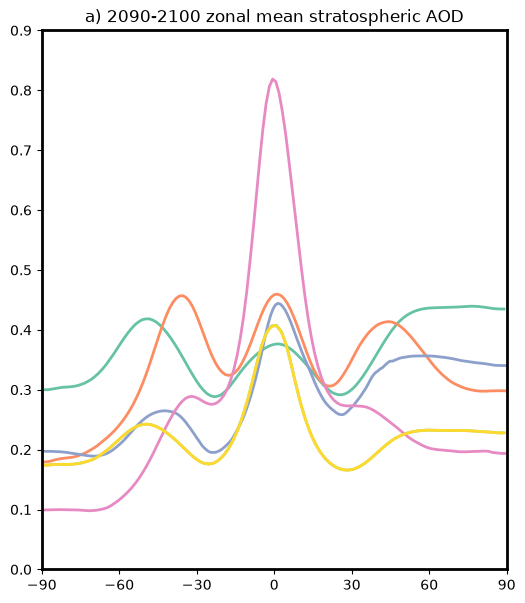

In [2]:
fc1 = brewermap(7, "Set2")
fig, ax = plt.subplots(figsize=(6, 7))
ax.plot(lat, x2_y_CNRM, color=fc1[0], linewidth=2)
ax.plot(lat_of(2), xl(2, 1) - xl(2, 3) * 0, color=fc1[1], linewidth=2)
ax.plot(lat_of(3), xl(3, 1) - xl(3, 3), color=fc1[2], linewidth=2)
ax.plot(lat_of(4), xl(4, 1) - xl(4, 3), color=fc1[3], linewidth=2)
ax.plot(lat2, x2_y_MPI, color=fc1[4], linewidth=2)
ax.plot(lat3, x2_y_MPIH, color=fc1[5], linewidth=2)
ax.set_title("a) 2090-2100 zonal mean stratospheric AOD")
ax.set_xticks(np.arange(-90, 91, 30)); ax.set_xlim(-90, 90); ax.set_ylim(0, .9)
for s in ax.spines.values():
    s.set_linewidth(2)
plt.show()

## Interpolate onto a common 2° grid and take the inter-model spread

In [3]:
lat_int1 = np.arange(-90, 91, 2.0)
aod_all = np.zeros((lat_int1.size, 6))
aod_all[:, 0] = interp1(lat, x2_y_CNRM, lat_int1, "linear", np.nan)
aod_all[:, 1] = interp1(lat_of(2), xl(2, 1) - xl(2, 3) * 0, lat_int1, "linear", np.nan)
aod_all[:, 2] = interp1(lat_of(3), xl(3, 1) - xl(3, 3), lat_int1, "linear", np.nan)
aod_all[:, 3] = interp1(lat_of(4), xl(4, 1) - xl(4, 3), lat_int1, "linear", np.nan)
aod_all[:, 4] = interp1(lat2, x2_y_MPI, lat_int1, "linear", np.nan)
aod_all[:, 5] = interp1(lat3, x2_y_MPIH, lat_int1, "linear", np.nan)

aod_all_std = np.std(aod_all, axis=1, ddof=1)
print("aod_all shape:", aod_all.shape, "| max inter-model std:", np.nanmax(aod_all_std))

# 2deg_tas.mat (provided input) is loaded by the MATLAB script for the
# subsequent (non-functional) figure(3); we load it for completeness.
td = mu.loadmat("2deg_tas.mat")
print("2deg_tas sulf_delta_std1 shape:", np.asarray(td["sulf_delta_std1"]).shape)

aod_all shape: (91, 6) | max inter-model std: 0.1654893957437286
2deg_tas sulf_delta_std1 shape: (91, 181)
